# RQ1 · Frequent ingredient pairs with A-Priori and PCY

We mine sets of normalized ingredients from Food.com recipes. A-Priori provides the exact baseline for each minimum support. PCY uses the same baskets and counts distinct candidate pairs in its second pass.


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

candidates = (Path.cwd() / "results", Path.cwd().parent / "results")
results = next(
    (path for path in candidates if (path / "itemsets_bench.csv").is_file()), None
)
if results is None:
    raise FileNotFoundError(
        "Expected results/itemsets_bench.csv near the notebook or repository root."
    )

In [2]:
bench = pd.read_csv(results / "itemsets_bench.csv")
rules = pd.read_csv(results / "rules_top.csv")
assert bench["exact_match_with_apriori"].eq(True).all()
display(bench.round({"elapsed_sec": 2, "peak_memory_mb": 2}))

,method,support,support_count,buckets,elapsed_sec,peak_memory_mb,candidate_pairs_counted,frequent_singles,frequent_pairs,exact_match_with_apriori
0,apriori,0.001,229,NaN,18.48,30.91,279315,995,5203,True
1,pcy,0.001,229,50000.0,122.47,7.48,62358,995,5203,True
2,pcy,0.001,229,100000.0,117.60,4.41,27211,995,5203,True
3,pcy,0.001,229,250000.0,119.98,4.25,12762,995,5203,True
4,apriori,0.005,1143,NaN,9.64,4.26,37848,286,700,True
5,pcy,0.005,1143,50000.0,101.12,0.86,1603,286,700,True
6,pcy,0.005,1143,100000.0,95.05,1.24,1113,286,700,True
7,pcy,0.005,1143,250000.0,92.97,2.57,860,286,700,True
8,apriori,0.010,2286,NaN,7.99,1.61,10366,146,274,True
9,pcy,0.010,2286,50000.0,86.68,0.64,361,146,274,True


Elapsed time and peak traced memory cover mining on prepared baskets. The comparison at 100,000 buckets matches the graph handoff configuration at 0.1% support.


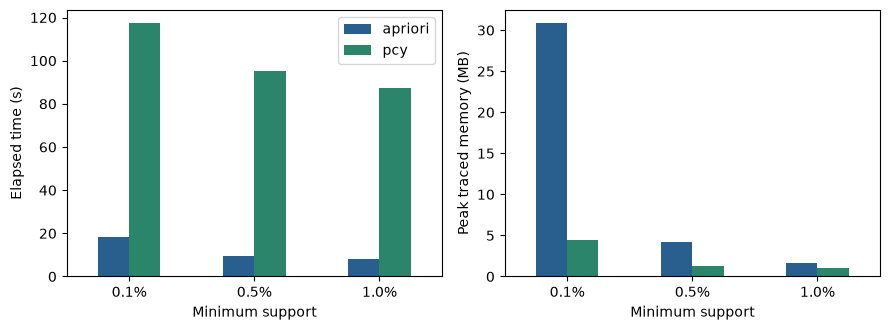

In [ ]:
comparison = bench.loc[bench["method"].eq("apriori") | bench["buckets"].eq(100_000)]
pivot = comparison.pivot(
    index="support", columns="method", values=["elapsed_sec", "peak_memory_mb"]
)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, field, label in zip(
    axes,
    ["elapsed_sec", "peak_memory_mb"],
    ["Elapsed time (s)", "Peak traced memory (MB)"],
):
    table = pivot[field].rename(index=lambda support: f"{support:.1%}")
    table.plot.bar(ax=ax, color=["#285f8f", "#2a856b"], rot=0, legend=False)
    ax.set(xlabel="Minimum support", ylabel=label)
axes[0].legend(title="")
fig.tight_layout()
plt.show()

In [ ]:
columns = [
    "min_support",
    "antecedent",
    "consequent",
    "pair_count",
    "support",
    "confidence",
    "lift",
]
display(rules.groupby("min_support", sort=False).head(5)[columns].round(4))

,min_support,antecedent,consequent,pair_count,support,confidence,lift
0,0.001,whole clove,cinnamon stick,350,0.0015,0.5109,65.8991
1,0.001,bread flour,active dry yeast,407,0.0018,0.3339,49.5813
2,0.001,yellow pepper,red pepper,257,0.0011,0.5762,48.1688
3,0.001,dry yeast,warm water,252,0.0011,0.4145,47.1501
4,0.001,active dry yeast,warm water,617,0.0027,0.4009,45.6071
20,0.005,ground coriander,ground cumin,1205,0.0053,0.5957,22.2545
21,0.005,dried basil,dried oregano,1287,0.0056,0.3996,18.9849
22,0.005,ground nutmeg,ground cinnamon,1340,0.0059,0.4616,15.5023
23,0.005,sesame oil,soy sauce,1643,0.0072,0.5590,14.7447
24,0.005,onion powder,garlic powder,2293,0.0100,0.6488,13.8353


Lift compares the observed pairing with the expectation under independence. The rules summarize co-occurrence in the dataset. The exported graph tables preserve pair counts, singleton counts, and the total number of baskets.
